# Historical Copper–Aluminum Relative Prices and World Copper Demand

**Reproducible retrospective demand-factor falsification, 1951–1975.** Original release vintages UNKNOWN; not equity alpha. The 15 sections follow `STUDY_TEMPLATE.md`. All plotted values and tables are computed from frozen observations and saved OOS tests.

## 01. Abstract

**Question:** Does a one-year-stale copper-versus-aluminum relative-price relief factor improve next-year world copper-consumption growth forecasts? In 10 purged expanding-window origins (1965–1974), the factor-augmented model reached **6.290 log-pp RMSE**, against **6.297** for demand/income/inventory controls and **7.625** for a historical mean. The **0.0068 log-pp** improvement is economically negligible, its block-bootstrap interval crosses zero, and longer horizons fail. **Verdict: historical macro-demand association only; no reliable lead factor or equity alpha.**

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from IPython.display import display
from analysis import (read_raw, make_panel, walk_forward, score, improvement,
                      block_bootstrap, block_shuffle_placebo, exposure_sensitivity,
                      ridge_forecast, CONTROLS, run_all)
%matplotlib inline
ROOT=Path.cwd()
summary=json.loads((ROOT/'results/summary.json').read_text())
print('Source observations:',summary['n_raw'],'OOS origins:',summary['n_oos'])
print('Primary gain (log-pp):',round(summary['rmse_gain_controls_minus_full'],6))

Source observations: 25 OOS origins: 10
Primary gain (log-pp): 0.006814


In [2]:
assert summary['not_pit'] and not summary['equity_returns_tested']
print('Research status: RETROSPECTIVE MACRO PILOT; PIT and equity alpha NOT established')

Research status: RETROSPECTIVE MACRO PILOT; PIT and equity alpha NOT established


## 02. Research Design & Hypotheses

**H1 (substitution):** lower lagged copper-price growth relative to aluminum predicts stronger next-year copper consumption growth. **H2 (incremental):** adding relative-cost relief to lagged consumption, income and inventory beats the fixed control model on purged expanding OOS RMSE. **H3 (stability):** improvement retains its sign across 2–3-year horizons, 1–3-year staleness, 1965–69/1970–74, block shuffles and weight perturbations. **Null:** no incremental predictive gain. Counterthesis: copper price reacts to demand/supply contemporaneously, substitution is technologically constrained, and annual aggregates are too coarse.

In [3]:
hypotheses=pd.DataFrame({'hypothesis':['H1 substitution','H2 incremental','H3 stability'],
'operational_test':['lagged relative-price signal versus forward consumption','full versus control OOS RMSE','horizon, lag, regimes, block placebo and perturbations'],
'failure_criterion':['sign/association not robust','RMSE gain <=0 or uncertain','gain reverses across credible specifications']})
display(hypotheses)

,hypothesis,operational_test,failure_criterion
0,H1 substitution,lagged relative-price signal versus forward co...,sign/association not robust
1,H2 incremental,full versus control OOS RMSE,RMSE gain <=0 or uncertain
2,H3 stability,"horizon, lag, regimes, block placebo and pertu...",gain reverses across credible specifications


In [4]:
print('Predeclared fixed rules: lag=1 annual observation; horizon=1 year; Ridge alpha=8; first OOS formation=1965')

Predeclared fixed rules: lag=1 annual observation; horizon=1 year; Ridge alpha=8; first OOS formation=1965


## 03. Industry Context

The original dataset describes **world copper consumption, 1951–1975** (3,173.0 to 7,157.2 thousand metric tonnes, *historical series only*), not current market size. Copper and aluminum compete in some industrial uses, while copper conductivity and application constraints limit substitution. The International Copper Association reported low substitution for **2020**, but this is **not** used as evidence for 1951–1975; the International Copper Study Group factbook is context only. Supply shocks, income growth and inventory cycles offer competing mechanisms; no company-level production exposure is measured.

In [5]:
raw=read_raw()
print('Historical consumption first/last (1000 metric tonnes):',raw.iloc[0].WORLDCONSUMPTION,raw.iloc[-1].WORLDCONSUMPTION)
print('Historical growth multiple:',round(raw.iloc[-1].WORLDCONSUMPTION/raw.iloc[0].WORLDCONSUMPTION,3))
display(raw[['year','WORLDCONSUMPTION','COPPERPRICE','ALUMPRICE']].head())

Historical consumption first/last (1000 metric tonnes): 3173.0 7157.2
Historical growth multiple: 2.256


,year,WORLDCONSUMPTION,COPPERPRICE,ALUMPRICE
0,1951,3173.0,26.56,19.76
1,1952,3281.1,27.31,20.78
2,1953,3135.7,32.95,22.55
3,1954,3359.1,33.90,23.06
4,1955,3755.1,42.70,24.93


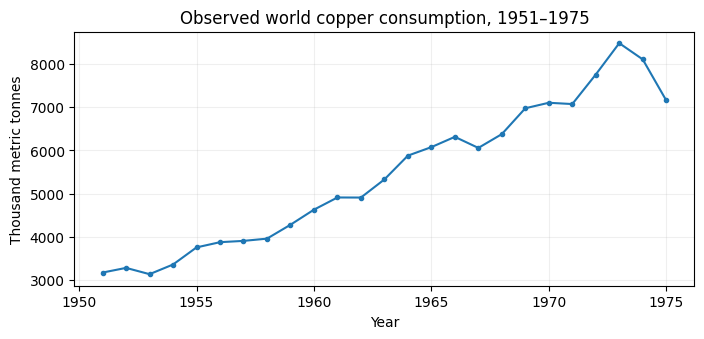

In [6]:
fig,ax=plt.subplots(figsize=(8,3.3));ax.plot(raw.year,raw.WORLDCONSUMPTION,marker='.',label='Copper consumption');ax.set(xlabel='Year',ylabel='Thousand metric tonnes',title='Observed world copper consumption, 1951–1975');ax.grid(alpha=.2);plt.show()

## 04. Data & Source Integrity

The **25 annual records** are frozen from `statsmodels 0.14.6` (Gill teaching panel). See `data/source_register.csv` for exact URLs, grades, original-release dates (**UNKNOWN**), observation periods, revision policy (**UNKNOWN**), copyright note and access date. Data QA asserts year continuity, positivity, no nulls, TIME-to-year mapping and spot checks. Frozen raw SHA-256: `e8fc38e9f887dc696f578baf7cd240b53648002d53135708ae97d3bde1800d37`. Grade B curated dataset, not official contemporaneous vintage; no fabricated corporate or securities data.

In [7]:
assert len(raw)==25 and raw.year.is_unique and raw.notna().all().all()
assert np.allclose(raw.TIME,raw.year-1950)
print('QA PASS: 25 complete consecutive years, TIME mapping, positive levels')
register=pd.read_csv('data/source_register.csv')
display(register[['grade','publisher','series','source_publication_date','revisions_vintage']])

QA PASS: 25 complete consecutive years, TIME mapping, positive levels


,grade,publisher,series,source_publication_date,revisions_vintage
0,B,statsmodels / Jeff Gill,World Copper Market 1951–1975,UNKNOWN,Statsmodels 0.14.6 package snapshot; original ...
1,B,statsmodels,Datasets package documentation,UNKNOWN,web documentation may change; access date frozen
2,A,International Copper Study Group,World Copper Factbook 2023,2023-10-09,website last updated 2026-10-15; not used in m...
3,B,International Copper Association,Copper Substitution Remains Low in 2020,2021-04-13,not used in historical regression


In [8]:
import hashlib
f=Path('data/copper_statsmodels_0_14_6_frozen.csv')
print('Frozen source SHA256:',hashlib.sha256(f.read_bytes()).hexdigest())

Frozen source SHA256: e8fc38e9f887dc696f578baf7cd240b53648002d53135708ae97d3bde1800d37


## 05. Point-in-Time Availability

At formation year **t**, all predictor features use **t−1 and t−2** only. Labels for a training origin j enter the fit only if **j+h ≤ t−1**; this purges overlapping targets and adds a conservative one-year label buffer. All standardization is computed on the training window only. **However historical actual release dates and revisions are UNKNOWN**, so this remains a retrospective fixed-snapshot experiment, not an authentic PIT backtest.

In [9]:
panel=make_panel(raw)
assert (panel.observed_through==panel.formation_year-1).all()
oos=walk_forward(panel)
assert (oos.last_train_target_year<=oos.formation_year-1).all()
display(oos[['formation_year','observed_through','target_year','last_train_target_year','n_train']])

,formation_year,observed_through,target_year,last_train_target_year,n_train
0,1965,1964,1966,1964,11
1,1966,1965,1967,1965,12
2,1967,1966,1968,1966,13
3,1968,1967,1969,1967,14
4,1969,1968,1970,1968,15
5,1970,1969,1971,1969,16
6,1971,1970,1972,1970,17
7,1972,1971,1973,1971,18
8,1973,1972,1974,1972,19
9,1974,1973,1975,1973,20


In [10]:
print('First admissible feature year:',int(panel.observed_through.min()))
print('First OOS target year:',int(oos.target_year.min()))
print('Unknown: historical original-release timestamps; fixed lag is NOT proof of PIT')

First admissible feature year: 1952
First OOS target year: 1966
Unknown: historical original-release timestamps; fixed lag is NOT proof of PIT


## 06. Factor Construction

Let \(g^P_{x,t}=100\log(P_{x,t-1}/P_{x,t-2})\). The fixed relative-cost relief factor is **\(F_t=-g^P_{Cu,t}+g^P_{Al,t}\)**, with unit weights and no optimized scaling. Positive F means copper inflation was lower than aluminum inflation in the *prior* year. The target is \(y_{t,h}=100\log(C_{t+h}/C_t)\). Controls are lagged consumption growth, lagged real-income-index growth and lagged inventory-index change. Weight perturbations test both factor coefficients in [0.75,1.25].

In [11]:
assert np.allclose(panel.relative_cost_relief,-panel.lag_copper_price_growth+panel.lag_aluminum_price_growth)
display(panel[['formation_year','relative_cost_relief','lag_demand_growth','lag_income_growth','y_growth']].head())

,formation_year,relative_cost_relief,lag_demand_growth,lag_income_growth,y_growth
0,1953,2.248468,3.350122,1.418463,6.882065
1,1954,-10.599425,-4.532630,1.398624,11.144184
2,1955,-0.605930,6.882065,-2.817088,3.166298
3,1956,-15.281152,11.144184,5.556985,0.765913
4,1957,-1.575809,3.166298,0.000000,1.320076


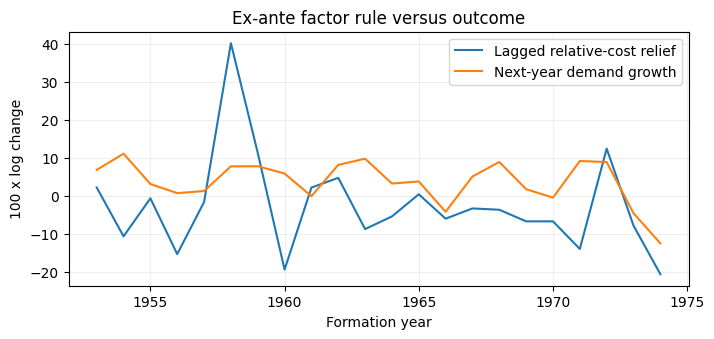

In [12]:
fig,ax=plt.subplots(figsize=(8,3.3));ax.plot(panel.formation_year,panel.relative_cost_relief,label='Lagged relative-cost relief');ax.plot(panel.formation_year,panel.y_growth,label='Next-year demand growth');ax.legend();ax.grid(alpha=.2);ax.set(xlabel='Formation year',ylabel='100 x log change',title='Ex-ante factor rule versus outcome');plt.show()

## 07. Exposure & Transmission

This is a **single world copper-demand series**, not a stock universe: sector exposure is 1 by construction, not an estimated firm loading. Aluminum substitution is a hypothesized transmission channel; income and inventory are confounders. `data/exposure_map.csv` explicitly labels mining equities and firm-level weights as **NOT ESTIMATED**. A leave-one-company-out test is **not applicable**; leave-one-OOS-year-out is supplied instead. No investable exposure is asserted.

In [13]:
exposure=pd.read_csv('data/exposure_map.csv');display(exposure)
print('Firm-level exposure estimates: NOT AVAILABLE; leave-one-company-out: NOT APPLICABLE')

,segment,exposure_to_relative_price_factor,weight,as_of,confidence,reason
0,World copper demand,lagged copper minus aluminum real price growth,1.0,1951-1975 dataset,B,No firm-level exposure estimates; sector-level...
1,Copper mining equities,NOT_ESTIMATED,NaN,UNKNOWN,UNKNOWN,No company universe or historical total returns
2,Aluminum substitute market,mechanism only,NaN,UNKNOWN,C,Not an independent outcome


Firm-level exposure estimates: NOT AVAILABLE; leave-one-company-out: NOT APPLICABLE


In [14]:
print('Substitution hypothesis sign: copper price growth enters with -1, aluminum price growth enters with +1')

Substitution hypothesis sign: copper price growth enters with -1, aluminum price growth enters with +1


## 08. Outcomes & Baselines

Outcome: next-year **world copper consumption log growth (log percentage points)**, with alternative 2- and 3-year cumulative horizons. All models use the **same 10 OOS origins** for the primary horizon. Baselines: expanding historical mean; last observable consumption growth (persistence); fixed Ridge (alpha=8) on lagged consumption, income and inventory; factor-only Ridge; and augmented Ridge with the same controls plus F. Training-only standardization, no tuned hyperparameters or full-sample z-score.

In [15]:
sc=score(oos)
display(sc)
assert sc.n_oos.nunique()==1 and sc.n_oos.iloc[0]==10

,model,n_oos,rmse,mae,mean_error
0,mean,10,7.624858,5.992499,3.371272
1,persistence,10,10.736764,9.246040,3.008847
2,controls,10,6.297079,4.556569,3.054085
3,full,10,6.290265,4.545102,3.063283
4,factor_only,10,7.363187,5.814537,3.198696


In [16]:
t=1965;train=panel[panel.target_year<=t-1];test=panel[panel.formation_year==t]
print('1965 origin, last allowed training label:',int(train.target_year.max()))
print('Control model prediction:',round(ridge_forecast(train,test,CONTROLS),5))
print('Augmented prediction:',round(ridge_forecast(train,test,CONTROLS+['relative_cost_relief']),5))

1965 origin, last allowed training label: 1964
Control model prediction: 3.3652
Augmented prediction: 3.37947


## 09. Empirical Findings

OOS origins **1965–1974 (n=10)**: historical mean **7.625**, persistence **10.737**, controls **6.297**, full **6.290**, factor-only **7.363** RMSE (log-pp). The control-minus-full gain **0.0068 log-pp** is tiny relative to errors. These are **10 historical annual observations**, not a statistically powerful out-of-sample panel. `results/oos_predictions.csv` contains each forecast, training size and final admissible label year.

In [17]:
print('Observed control-minus-full RMSE gain:',improvement(oos))
display(oos[['formation_year','actual','mean','persistence','controls','full','factor_only']])

Observed control-minus-full RMSE gain: 0.0068135267528761645


,formation_year,actual,mean,persistence,controls,full,factor_only
0,1965,3.834857,5.713020,9.832745,3.365196,3.379470,5.713841
1,1966,-4.138187,5.511354,3.293029,5.710316,5.713849,5.362319
2,1967,5.134365,5.382393,3.834857,5.548031,5.539855,5.298487
3,1968,8.970671,4.702351,-4.138187,7.600178,7.590984,4.578902
4,1969,1.808815,4.731152,5.134365,4.138015,4.136210,4.492865
5,1970,-0.421921,4.996122,8.970671,3.870988,3.884204,4.778302
6,1971,9.221110,4.808633,1.808815,6.012959,6.011834,4.272615
7,1972,8.943382,4.518047,-0.421921,6.479267,6.578638,5.204439
8,1973,-4.524000,4.765577,9.221110,1.999243,2.001402,4.574525
9,1974,-12.438699,4.974467,8.943382,2.207053,2.186780,4.101059


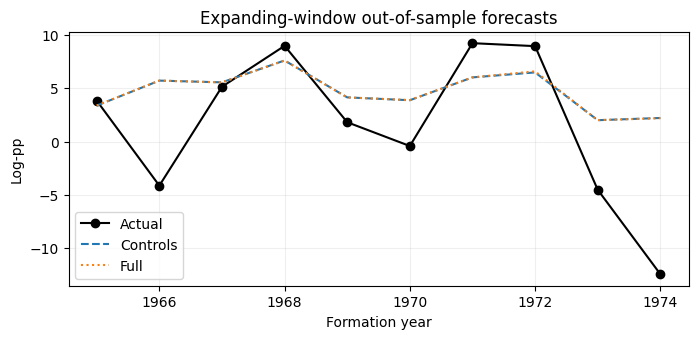

In [18]:
fig,ax=plt.subplots(figsize=(8,3.3));ax.plot(oos.formation_year,oos.actual,'k-o',label='Actual');ax.plot(oos.formation_year,oos.controls,'--',label='Controls');ax.plot(oos.formation_year,oos.full,':',label='Full');ax.legend();ax.grid(alpha=.2);ax.set(xlabel='Formation year',ylabel='Log-pp',title='Expanding-window out-of-sample forecasts');plt.show()

Mean paired squared-error gain: 0.08576420663922134 n= 10


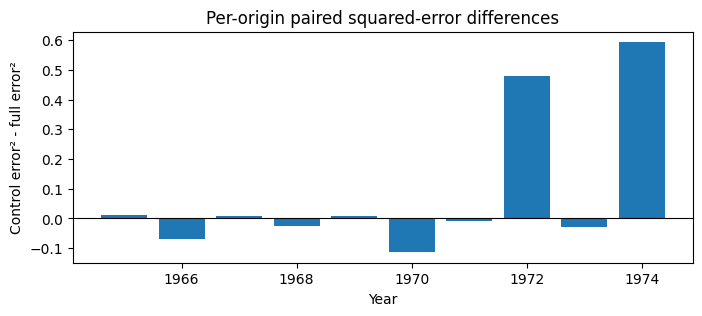

In [19]:
paired_loss=(oos.actual-oos.controls)**2-(oos.actual-oos.full)**2
print('Mean paired squared-error gain:',paired_loss.mean(),'n=',len(paired_loss))
fig,ax=plt.subplots(figsize=(8,3));ax.bar(oos.formation_year,paired_loss);ax.axhline(0,color='black',lw=.8);ax.set(title='Per-origin paired squared-error differences',xlabel='Year',ylabel='Control error² - full error²');plt.show()

## 10. Robustness & Placebos

**1,000** three-year-block reordering placebo refits yielded exploratory upper-tail fraction **0.273** (not an exact p-value). **2,000** paired circular three-year-block bootstrap draws gave a 95% percentile interval **[-0.0040, 0.0155] log-pp**, crossing zero. **1,000** independent copper/aluminum weight perturbations were positive **66.5%** of the time; this is not independent evidence because weights are near the original. Leave-one-year-out, no-income/no-inventory ablations and 2–3-year horizons are computed in `results/`.

In [20]:
placebo=pd.read_csv('results/block_shuffle_1000.csv');boot=pd.read_csv('results/block_bootstrap_2000.csv')
assert len(placebo)==1000 and len(boot)==2000
p_tail=(1+(placebo.rmse_gain>=improvement(oos)).sum())/(len(placebo)+1)
print('Exploratory block-reordering tail fraction:',p_tail)
print('Paired block-bootstrap 95% percentiles:',np.quantile(boot.rmse_gain,[.025,.975]))

Exploratory block-reordering tail fraction: 0.2727272727272727
Paired block-bootstrap 95% percentiles: [-0.00398357  0.01547842]


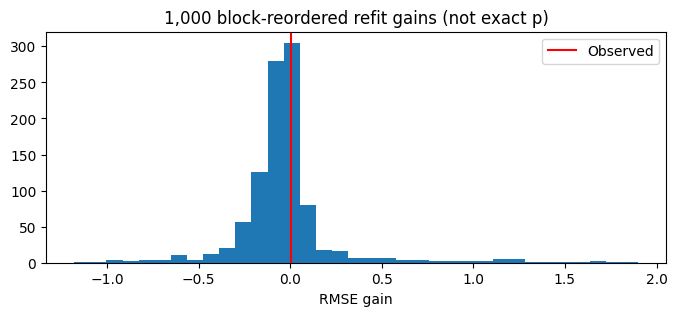

In [21]:
fig,ax=plt.subplots(figsize=(8,3));ax.hist(placebo.rmse_gain,bins=35);ax.axvline(improvement(oos),color='red',label='Observed');ax.legend();ax.set(title='1,000 block-reordered refit gains (not exact p)',xlabel='RMSE gain');plt.show()

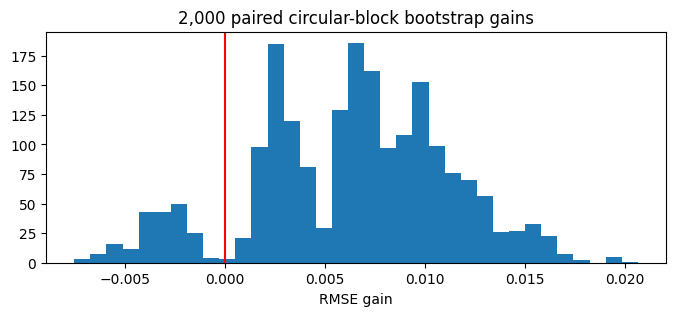

In [22]:
fig,ax=plt.subplots(figsize=(8,3));ax.hist(boot.rmse_gain,bins=35);ax.axvline(0,color='red');ax.set(title='2,000 paired circular-block bootstrap gains',xlabel='RMSE gain');plt.show()

In [23]:
expo=pd.read_csv('results/exposure_perturbations_1000.csv')
assert len(expo)==1000
print('Positive gain under ±25% independent weights:',round(100*(expo.rmse_gain>0).mean(),1),'%')
display(pd.read_csv('results/leave_one_year_out.csv'))

Positive gain under ±25% independent weights: 66.5 %


,excluded_year,n_oos,rmse_gain
0,1965,9,0.007073
1,1966,9,0.008936
2,1967,9,0.007128
3,1968,9,0.007412
4,1969,9,0.007161
5,1970,9,0.008331
6,1971,9,0.007339
7,1972,9,0.003187
8,1973,9,0.007852
9,1974,9,0.003265


## 11. Regime Sensitivity

1965–1969 (n=5) control-minus-full RMSE gain **-0.0015**, 1970–1974 (n=5) **+0.0121**. Excluding formation years 1973–1974 yields **+0.0044** (n=8). The two-year horizon gain is **-0.2154** and three-year gain **-0.3857**. These tiny subperiods are descriptive only; none validates a stable effect.

In [24]:
regimes=pd.read_csv('results/regime_sensitivity.csv');robust=pd.read_csv('results/robustness.csv')
display(regimes);display(robust)

,regime,n_oos,rmse_gain
0,1965-1969,5,-0.001455
1,1970-1974,5,0.012107
2,exclude_1973_1974,8,0.004379


,scenario,horizon,lag,first,n_oos,rmse_gain,rmse_controls,rmse_full
0,primary,1,1,1965,10,0.006814,6.297079,6.290265
1,h2,2,1,1965,9,-0.215356,9.749231,9.964587
2,h3,3,1,1965,8,-0.385717,9.568039,9.953756
3,lag2,1,2,1965,10,-0.263904,7.359410,7.623314
4,lag3,1,3,1965,10,0.002088,7.155333,7.153245
5,no_inventory,1,1,1965,10,0.017035,6.271202,6.254167
6,no_income,1,1,1965,10,0.052085,6.523787,6.471701
7,exclude_1973_1974,1,1,1965,8,0.004379,4.175543,4.171164


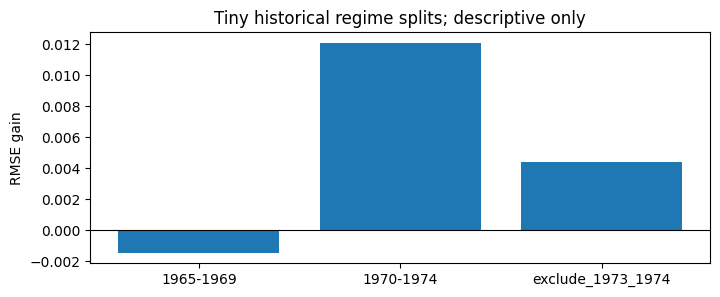

In [25]:
fig,ax=plt.subplots(figsize=(8,3));ax.bar(regimes.regime,regimes.rmse_gain);ax.axhline(0,color='black',lw=.8);ax.set(title='Tiny historical regime splits; descriptive only',ylabel='RMSE gain');plt.show()

## 12. Bias Audit & Verdict

**Publication/revision leakage:** original vintages unknown, cannot certify PIT. **Selection:** Gill's 25-year teaching sample, historical endpoint and a single world series are ex-post selected. **Endogeneity:** prices can react to demand and inventories. **Overlapping targets:** purged training, but OOS errors serially dependent; block bootstrap has only ten origins. **Multiple testing:** horizon/lag/ablation checks are exploratory and not corrected; do not promote best subgroup. **Survivorship:** no security universe exists. **Costs/capacity:** no tradable strategy or transaction costs. **Verdict:** tiny, unstable retrospective demand forecast gain; neither validated modern copper signal nor equity alpha.

In [26]:
audit=pd.DataFrame({'risk':['Original release-vintage leakage','Demand/price simultaneity','Single historical series','Small and serially correlated OOS','Multiple-testing / subgroup selection','Survivorship and costs'],
'assessment':['UNVERIFIED','HIGH','HIGH','HIGH','HIGH','NOT APPLICABLE to untested equities']})
display(audit)

,risk,assessment
0,Original release-vintage leakage,UNVERIFIED
1,Demand/price simultaneity,HIGH
2,Single historical series,HIGH
3,Small and serially correlated OOS,HIGH
4,Multiple-testing / subgroup selection,HIGH
5,Survivorship and costs,NOT APPLICABLE to untested equities


In [27]:
assert np.quantile(boot.rmse_gain,.025)<0<np.quantile(boot.rmse_gain,.975)
assert robust.loc[robust.scenario=='h2','rmse_gain'].iloc[0]<0
print('VERDICT: No stable, modern or investable alpha established.')

VERDICT: No stable, modern or investable alpha established.


## 13. Reproduction

From this folder: `python run_analysis.py`, `python -m pytest -q tests`, and `OPENBLAS_NUM_THREADS=1 jupyter nbconvert --to notebook --execute research.ipynb --output reproduced.ipynb`. All source and output tables are versioned. The code uses deterministic RNG seed **20261027** and fixed Ridge alpha **8.0**. Logs under `logs/` record actual execution. From repository root run `python scripts/validate_studies.py`; its structural success does **not** prove PIT validity.

In [28]:
import importlib.metadata as meta
print('Environment:',{p:meta.version(p) for p in ['numpy','pandas','matplotlib','statsmodels']})
print('Reproduction command: OPENBLAS_NUM_THREADS=1 python run_analysis.py')

Environment: {'numpy': '2.3.5', 'pandas': '2.2.3', 'matplotlib': '3.10.8', 'statsmodels': '0.14.6'}
Reproduction command: OPENBLAS_NUM_THREADS=1 python run_analysis.py


In [29]:
# Independently reconstruct one OOS row without reading saved prediction columns.
origin=1967;tr=panel[panel.target_year<=origin-1];te=panel[panel.formation_year==origin]
pred=ridge_forecast(tr,te,CONTROLS+['relative_cost_relief'])
stored=oos.loc[oos.formation_year==origin,'full'].iloc[0]
assert np.isclose(pred,stored,atol=1e-10)
print('Independent 1967 OOS recomputation matches saved table:',pred)

Independent 1967 OOS recomputation matches saved table: 5.53985471716681


## 14. Next-Stage Protocol

Obtain monthly first-release refined-copper usage from ICSG, original-date aluminum/copper spot/futures quotes, independently dated GDP/industrial output and inventories; freeze publication timestamps and revision vintages. Build a preregistered modern 2000–2026 monthly design with expanding purged OOS, holdout post-2022, sector-neutral mining/smelting company exposure from contemporaneous filings and delisting-inclusive total returns. Include futures carry, slippage, fees, capacity, multiple-testing adjustment and genuine historical constituent universes. Until then, **do not trade on this pilot**.

In [30]:
protocol=pd.DataFrame({'next_data':['ICSG first-release monthly usage','Dated metal prices/futures','Original vintage income & inventory','Contemporaneous firm filings and security total returns'],
'required_check':['release archive & revisions','price date and units','timestamp and no lookahead','historical universe, delistings and costs']})
display(protocol)

,next_data,required_check
0,ICSG first-release monthly usage,release archive & revisions
1,Dated metal prices/futures,price date and units
2,Original vintage income & inventory,timestamp and no lookahead
3,Contemporaneous firm filings and security tota...,"historical universe, delistings and costs"


In [31]:
print('Pre-registration required before modern study; this 25-year teaching panel cannot justify live deployment.')

Pre-registration required before modern study; this 25-year teaching panel cannot justify live deployment.


## 15. Sources & Artifacts

**Primary:** [statsmodels World Copper Market 1951–1975](https://www.statsmodels.org/0.9.0/datasets/generated/copper.html), Gill dataset; access 2026-10-27, original release date UNKNOWN. **Context:** [ICSG Factbook 2023](https://icsg.org/download/factbook2023/) (published 2023-10-09) and [International Copper Association substitution note](https://internationalcopper.org/resource/copper-substitution-remains-low-in-2020/) (2021-04-13). **Artifacts:** `data/` frozen observations, SHA and register; `results/` OOS and 1000/2000-draw tables; `figures/` ten computed SVGs; `analysis.py`, `make_figures.py`, `tests/`, `research.ipynb`, `logs/`. Historical source release dates and revision histories remain **UNKNOWN**.

In [32]:
print('Frozen raw data:',Path('data/copper_statsmodels_0_14_6_frozen.csv').stat().st_size,'bytes')
print('Computed figures:',len(list(Path('figures').glob('*.svg'))))
print('Placebo rows:',len(placebo),'Bootstrap rows:',len(boot),'Perturbation rows:',len(expo))
print('Source register entries:',len(register))

Frozen raw data: 1028 bytes
Computed figures: 10
Placebo rows: 1000 Bootstrap rows: 2000 Perturbation rows: 1000
Source register entries: 4


In [33]:
display(register[['grade','publisher','url','observation_period','release_lag']])
print('Explicit limitation: not point-in-time; no issuer fundamentals or equity total returns.')

,grade,publisher,url,observation_period,release_lag
0,B,statsmodels / Jeff Gill,https://www.statsmodels.org/0.9.0/datasets/gen...,1951–1975,UNKNOWN
1,B,statsmodels,https://www.statsmodels.org/stable/datasets/in...,not applicable,not applicable
2,A,International Copper Study Group,https://icsg.org/download/factbook2023/,modern market context; not used in regressions,not applicable
3,B,International Copper Association,https://internationalcopper.org/resource/coppe...,2020,not applicable


Explicit limitation: not point-in-time; no issuer fundamentals or equity total returns.
